# 11 — Interpretasi SHAP Otomatis (3 Model Wakil)

SHAP dihitung untuk **tiga model yang dipilih otomatis** dari hasil notebook 09 (`wakil_model.json`):

1. **DPformer** (model usulan);
2. **DL baseline terbaik** dari 10 baseline (peringkat rata-rata MAE dalam kelompok);
3. **ML terbaik** dari 10 model ML.

Konfigurasi representatif: **multivariat, h = 20**. Aturan anti-kebocoran: *background* = baris **train** saja; sampel yang dijelaskan = baris **uji** (tidak ikut melatih apa pun); model tidak dilatih ulang kecuali bobot tidak tersimpan (lalu diverifikasi terhadap MAE run utama).

**Penjelas.** ML: `TreeExplainer` (LightGBM, XGBoost, RF, ExtraTrees, CatBoost, GBM), `LinearExplainer` (ElasticNet), `PermutationExplainer` (AdaBoost, HistGB, SVR). DL: `shap.GradientExplainer` (*expected gradients*); bila gagal pada arsitektur/versi tertentu, implementasi expected-gradients sendiri (prinsip identik) dipakai.
**Satuan seragam.** Semua nilai dikonversi ke **kontribusi terhadap return 20-hari (poin persen)** dan diagregasi per **variabel** (Antam: lag & rolling dijumlahkan; 7 makro), sehingga model ML dan DL sebanding dan sifat aditif Shapley terjaga.

**Catatan.** Bao et al. (2026) memakai pendekatan atribusi sendiri (prior attention + integrated gradients, Eq. 23–26) tanpa kode lengkap; yang dipakai di sini adalah SHAP standar yang dapat direproduksi — **bukan klaim reproduksi identik**. SHAP menjelaskan *perilaku model*, bukan hubungan sebab-akibat pasar.

In [1]:
import sys, os, json, time, warnings

# Batasi thread CPU supaya laptop tetap responsif selama training berjam-jam.
# Default 2 thread. Ubah lewat env TA_THREADS. Harus di kernel BARU (sebelum numpy/tensorflow aktif).
N_THREADS = int(os.environ.get('TA_THREADS', '2'))
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(_v, str(N_THREADS))

sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
try:
    tf.config.threading.set_intra_op_parallelism_threads(N_THREADS)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    print('[PERHATIAN] TensorFlow sudah aktif di kernel ini, batas thread tidak berlaku. Restart kernel.')

from src.config import (OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK,
                        SEQ_LEN, EPOCHS, PATIENCE, BASE_LR, BASE_WD, DL_BATCH, DL_UNITS)
from src import analysis as A, plots as P, stats as S, runners as R
from src.pipeline import SEED, load_mossa, free_memory
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
RUNS = os.path.join(RES, 'runs')
FIGS = os.path.join(OUT, 'figures')
MODEL_DIR = os.path.join(RES, 'models')
for _d in (RES, RUNS, FIGS, MODEL_DIR):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))


def simpan(fig, nama):
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

import shap
from src import explain as E
from src.config import SHAP_SETUP, SHAP_H, SHAP_N_BACKGROUND, SHAP_N_EXPLAIN, SHAP_NSAMPLES
from src.pipeline import build_dl_explain_arrays, EXO_COLS
from src.models_dl import BUILDERS

SHAP_DIR = os.path.join(RES, 'shap')
os.makedirs(SHAP_DIR, exist_ok=True)
H = SHAP_H
print('SHAP', shap.__version__, '| setup', SHAP_SETUP, '| h', H, '| background', SHAP_N_BACKGROUND, '| sampel dijelaskan', SHAP_N_EXPLAIN)

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44
SHAP 0.53.0 | setup multivariat | h 20 | background 50 | sampel dijelaskan 100


## 1. Pemilihan model otomatis

In [2]:
wakil = A.load_wakil(RES)
tab = pd.read_csv(os.path.join(RES, 'tabel_hasil_final.csv'))
KIND = {'dpformer': wakil['dpformer'], 'dl': wakil['dl'], 'ml': wakil['ml']}
print('Model yang dijelaskan:', KIND)
print('Kriteria:', wakil['kriteria'])
display(pd.read_csv(os.path.join(RES, 'ranking_kelompok_dl.csv')).head(4).round(3))
display(pd.read_csv(os.path.join(RES, 'ranking_kelompok_ml.csv')).head(4).round(3))

Model yang dijelaskan: {'dpformer': 'dpformer', 'dl': 'gru_att', 'ml': 'adaboost'}
Kriteria: peringkat rata-rata MAE dalam kelompok (2 setup x horizon); seri: rata-rata pct_vs_drift; DPformer tetap


,model,mean_rank,wins,mean_MAE,mean_pct_vs_drift
0,gru_att,3.6,1,46306.854,0.244
1,lstm_att,3.7,1,46254.722,0.254
2,patchtst,4.0,2,46160.014,0.328
3,lstm,4.8,0,46464.850,-0.012


,model,mean_rank,wins,mean_MAE,mean_pct_vs_drift
0,adaboost,1.5,6,45131.170,2.394
1,rf,3.5,2,45450.538,1.213
2,elasticnet,3.7,0,46018.008,0.756
3,extra_trees,4.7,0,45901.562,0.377


## 2. Hitung SHAP

- DPformer: bobot terbaik h=20 dari notebook 05 (tanpa melatih ulang).
- DL baseline terpilih: bobot dari notebook 06; bila tidak ada (hasil lama dipakai ulang), model itu dilatih ulang dengan seed/konfigurasi yang sama dan **MAE-nya dibandingkan dengan run utama**.
- ML terpilih: dilatih ulang (deterministik, konfigurasi identik) dan prediksinya **dicocokkan** dengan prediksi tersimpan.

In [3]:
def stored_mae(m):
    return float(tab[(tab.setup == SHAP_SETUP) & (tab.model == m) & (tab.horizon == H)].MAE.iloc[0])


def lr_wd(m):
    if m == 'dpformer':
        ms = load_mossa(os.path.join(RES, 'mossa_dpformer.json'))
        return ms[SHAP_SETUP][0], ms[SHAP_SETUP][1]
    return BASE_LR, BASE_WD


_, _, rows_ex = build_dl_explain_arrays(p, exo, H, SEQ_LEN, SHAP_N_BACKGROUND, SHAP_N_EXPLAIN, 42)
HASIL, INFO = {}, {}
for kind in ('dpformer', 'dl', 'ml'):
    m = KIND[kind]
    t0 = time.time()
    if kind in ('dpformer', 'dl'):
        lr, wd = lr_wd(m)
        wp = os.path.join(MODEL_DIR, f'{m}_{SHAP_SETUP}_h{H}.weights.h5')
        model, info = E.get_dl_model(p, exo, m, H, wp, BUILDERS, SEQ_LEN, DL_UNITS[m], DL_BATCH[m], lr, wd, EPOCHS, PATIENCE,
                                     stored_mae=stored_mae(m))
        if info['sumber'] == 'dilatih_ulang' and info.get('selisih_rel', 0) > 0.01:
            print(f"  [PERHATIAN] {m} dilatih ulang dan MAE berbeda {info['selisih_rel'] * 100:.2f}% dari run utama; laporkan.")
        res = E.explain_dl(p, exo, model, H, SEQ_LEN, SHAP_N_BACKGROUND, SHAP_N_EXPLAIN, nsamples=SHAP_NSAMPLES)
        free_memory()
    else:
        info = {'sumber': 'dilatih_ulang_deterministik'}
        res = E.explain_ml(p, exo, m, H, rows_ex, SHAP_N_BACKGROUND, 42, stored_pred=A.read_pred(RES, SHAP_SETUP, m, H))
        info['repro_maxrel_diff'] = res['repro_maxrel_diff']
        if res['repro_maxrel_diff'] is not None and res['repro_maxrel_diff'] > 1e-6:
            print(f"  [PERHATIAN] prediksi model ML yang dilatih ulang berbeda {res['repro_maxrel_diff']:.2e} dari run utama")
    res['h'] = H
    tag = f'{kind}_{m}'
    meta = E.save_result(res, SHAP_DIR, tag)
    HASIL[kind] = res
    INFO[kind] = {'model': m, 'tag': tag, **info, 'metode': res['method'], 'completeness_err': res['completeness_err'], 'detik': round(time.time() - t0, 1)}
    print(f"{kind:9s} {m:12s} metode={res['method']:24s} sumber={info['sumber']:28s} galat kelengkapan={res['completeness_err']:.3f} ({INFO[kind]['detik']} dtk)")
with open(os.path.join(SHAP_DIR, 'shap_ringkasan.json'), 'w', encoding='utf-8') as f:
    json.dump({'setup': SHAP_SETUP, 'h': H, 'wakil': KIND, 'info': INFO, 'n_background': SHAP_N_BACKGROUND, 'n_explain': SHAP_N_EXPLAIN}, f, indent=1, default=str)

c:\Users\wildnrfm\Downloads\antam_forecasting\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(100, 10, 8))']
  warnings.warn(msg)
c:\Users\wildnrfm\Downloads\antam_forecasting\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(50, 10, 8))']
  warnings.warn(msg)


dpformer  dpformer     metode=shap.GradientExplainer   sumber=bobot_tersimpan              galat kelengkapan=0.098 (18.4 dtk)


c:\Users\wildnrfm\Downloads\antam_forecasting\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(100, 10, 8))']
  warnings.warn(msg)
c:\Users\wildnrfm\Downloads\antam_forecasting\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(50, 10, 8))']
  warnings.warn(msg)


dl        gru_att      metode=shap.GradientExplainer   sumber=bobot_tersimpan              galat kelengkapan=0.097 (11.2 dtk)
ml        adaboost     metode=PermutationExplainer     sumber=dilatih_ulang_deterministik  galat kelengkapan=0.000 (158.0 dtk)


## 3. Figur: (a) rata-rata |SHAP|, (b) beeswarm (warna = nilai variabel), (c) porsi

Satuan: poin persen return 20-hari. **Galat kelengkapan** = |(nilai dasar + Σ SHAP) − prediksi| relatif terhadap simpangan prediksi; ≈ 0 untuk TreeExplainer/Linear, kecil (bukan nol) untuk estimasi expected-gradients/permutation.

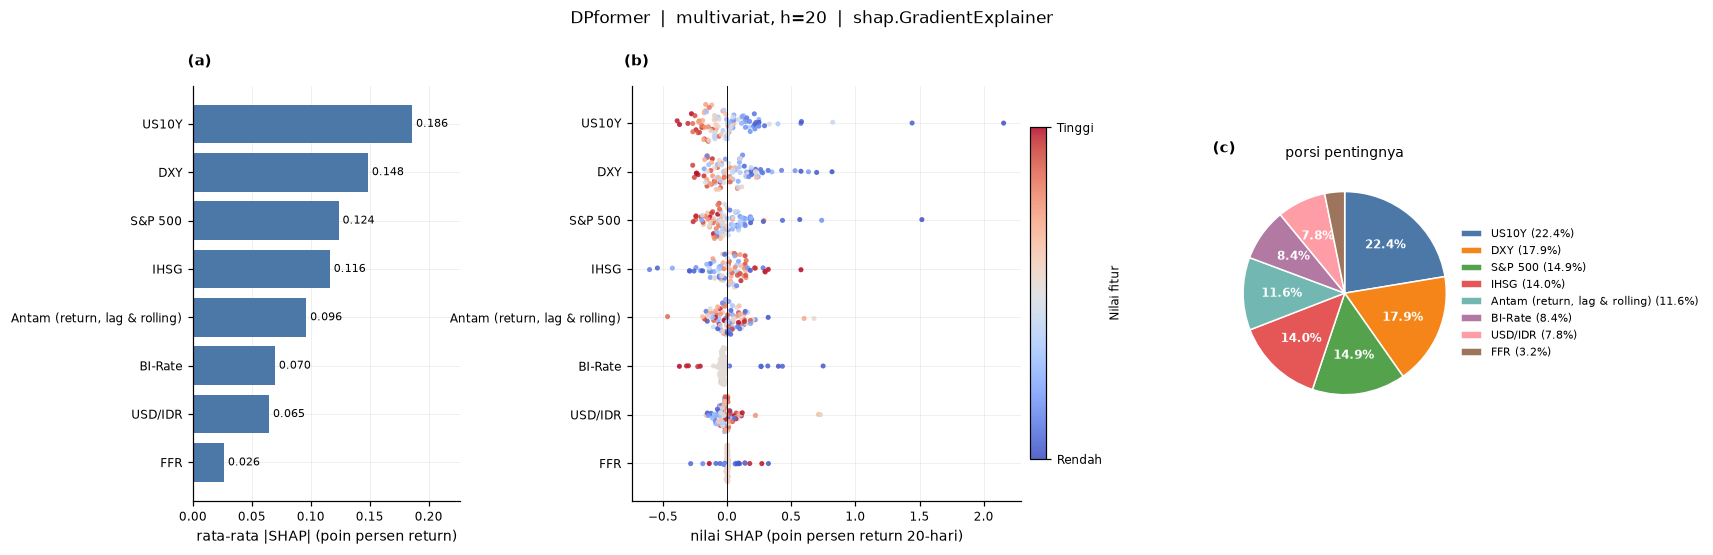

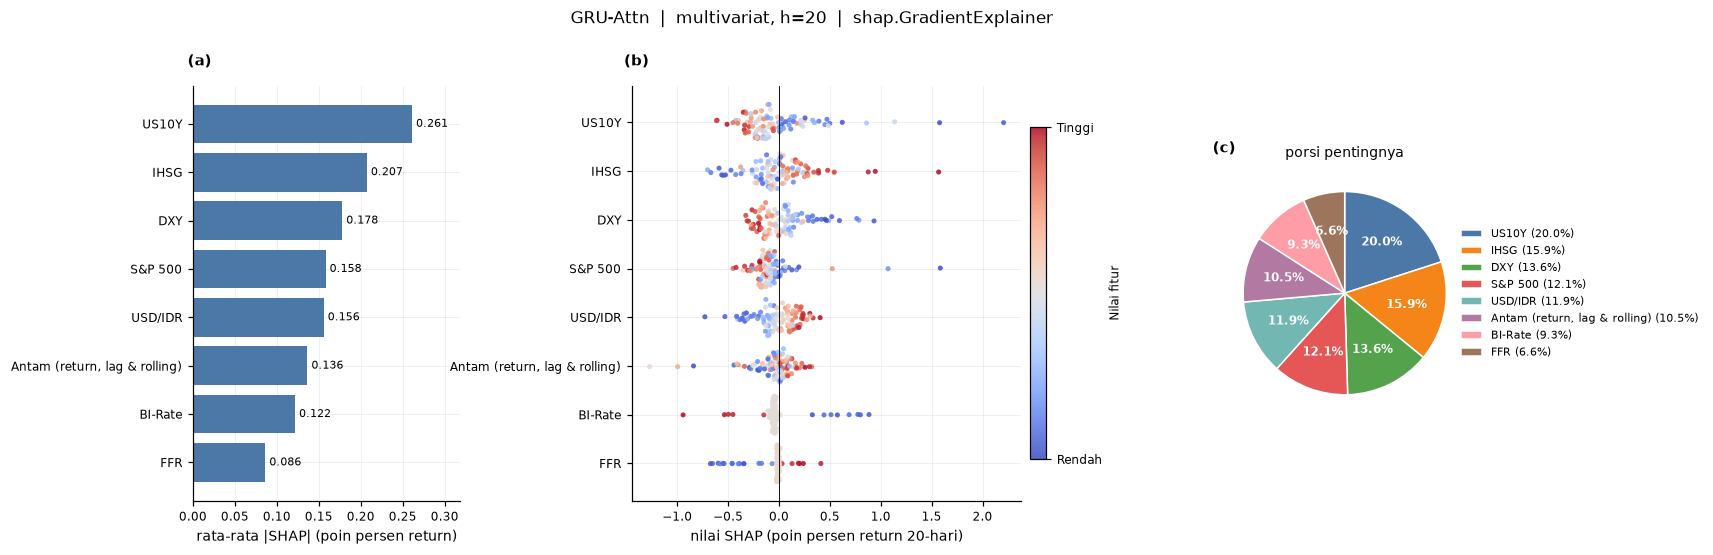

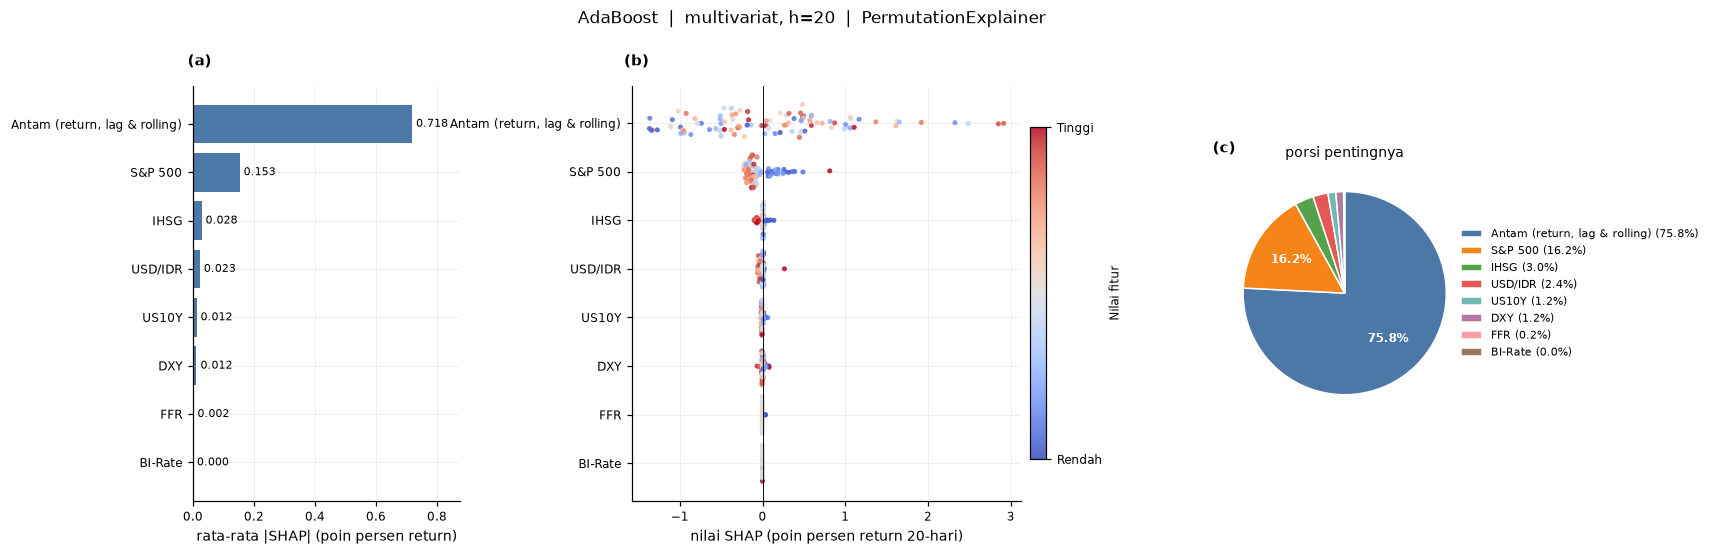

In [4]:
for kind in ('dpformer', 'dl', 'ml'):
    m = KIND[kind]
    fig = P.fig_shap_summary(HASIL[kind], title=f'{P.label(m)}  |  {SHAP_SETUP}, h={H}  |  {HASIL[kind]["method"]}')
    simpan(fig, f'fig_shap_ringkasan_{kind}_{m}')

## 4. Penjelasan satu prediksi (waterfall, gaya Fig. 9 jurnal)

Sampel = hari uji dengan simpangan prediksi terbesar dari nilai dasar (dipilih deterministik, bukan "yang terlihat bagus").

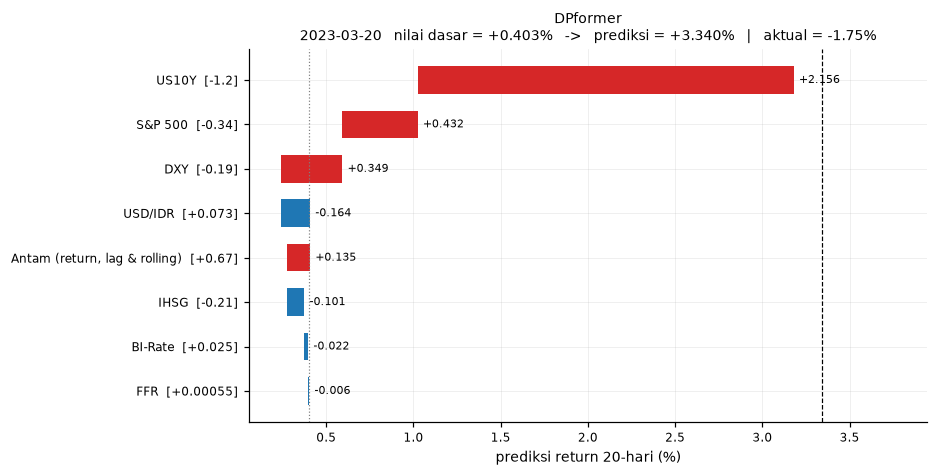

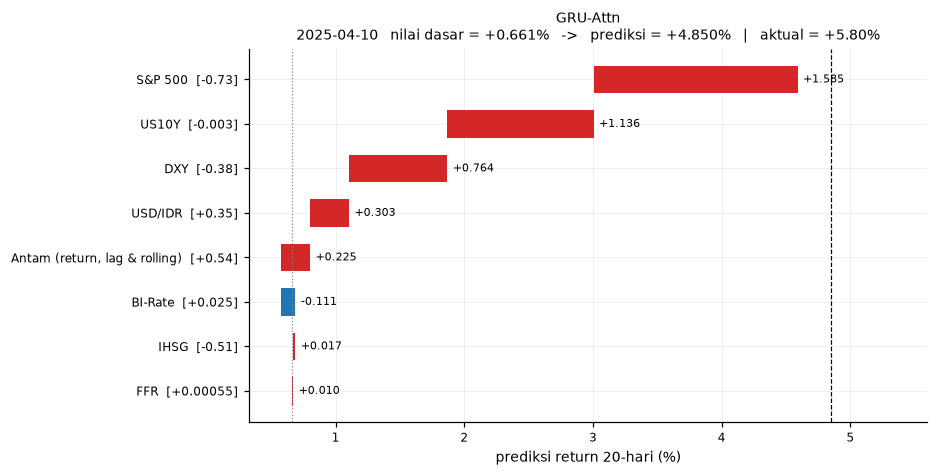

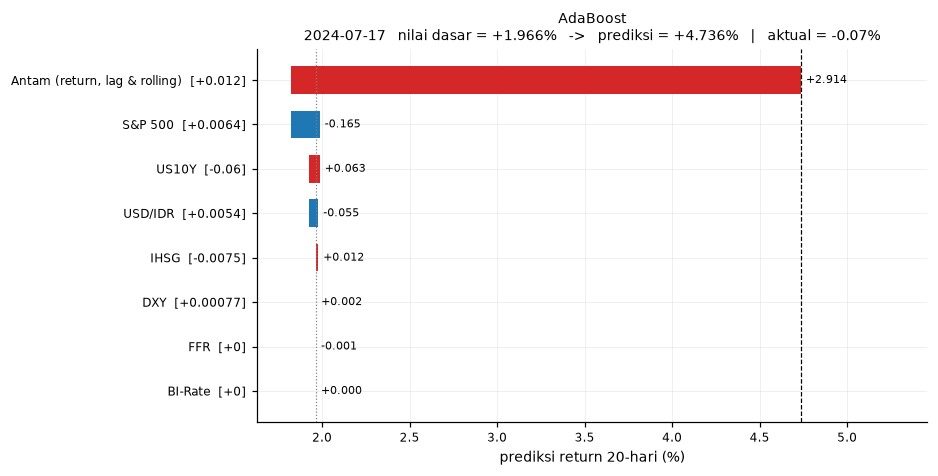

In [5]:
R20 = p.shift(-H) / p - 1
for kind in ('dpformer', 'dl', 'ml'):
    m, res = KIND[kind], HASIL[kind]
    i = E.pick_waterfall_sample(res)
    act = float(R20.loc[res['dates'][i]])
    fig = P.fig_shap_waterfall(res, i, title=P.label(m), actual=act)
    simpan(fig, f'fig_shap_waterfall_{kind}_{m}')

## 5. Perbandingan tiga model: porsi pentingnya per variabel

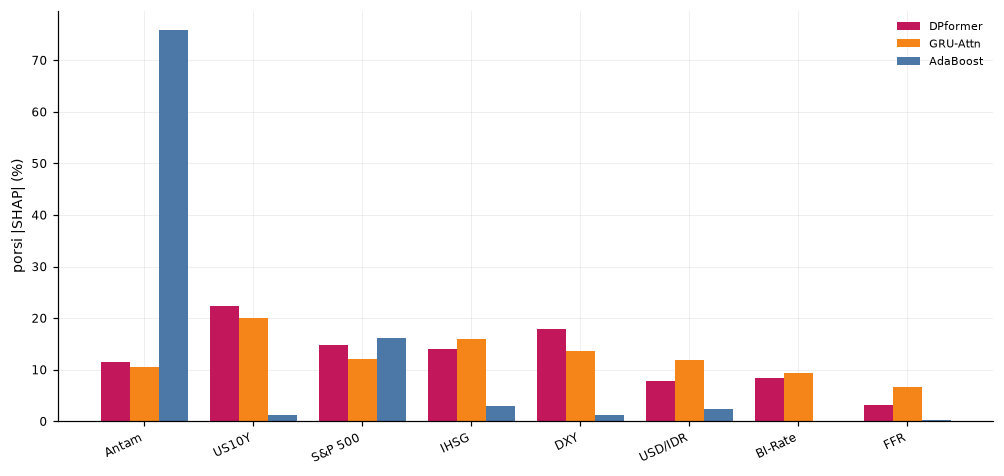

,DPformer,GRU-Attn,AdaBoost
variabel,,,
us10yr,22.4,20.0,1.2
dxy,17.9,13.6,1.2
sp500,14.9,12.1,16.2
ihsg,14.0,15.9,3.0
emas,11.6,10.5,75.8
bi_rate,8.4,9.3,0.0
usd_idr,7.8,11.9,2.4
ffr,3.2,6.6,0.2


In [6]:
tabs = {KIND[k]: E.importance_table(HASIL[k]) for k in ('dpformer', 'dl', 'ml')}
fig = P.fig_shap_compare(tabs)
simpan(fig, 'fig_shap_perbandingan')
gabung = pd.concat({P.label(m): t.set_index('variabel').porsi_pct for m, t in tabs.items()}, axis=1).round(1)
gabung.to_csv(os.path.join(SHAP_DIR, 'shap_porsi_per_model.csv'))
display(gabung)

## 6. Atribusi menurut langkah waktu (DL)

Rata-rata |atribusi| per hari dalam jendela 10 hari (hari paling baru di kanan) dan per variabel. Menunjukkan apakah model memakai informasi terkini atau tersebar merata.

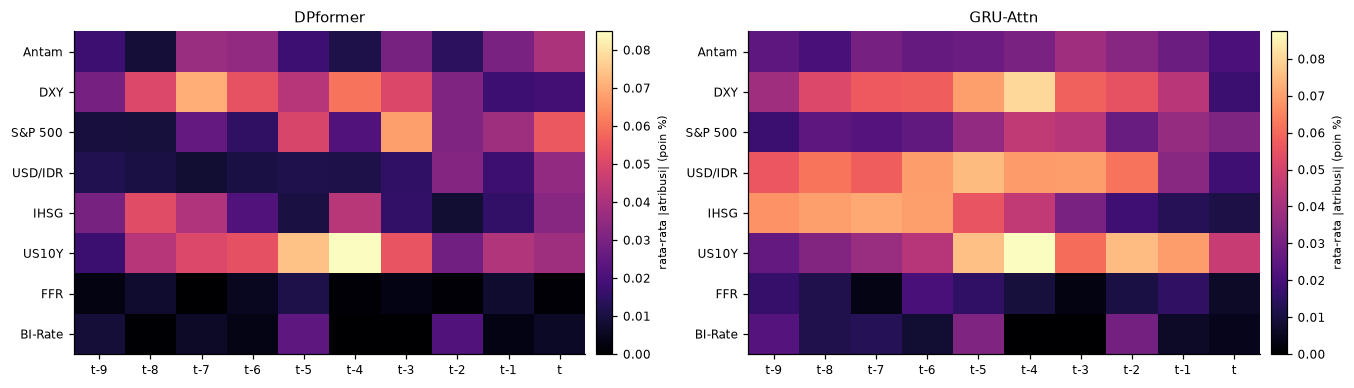

In [7]:
dl_kinds = [k for k in ('dpformer', 'dl') if 'phi_time' in HASIL[k]]
fig, axs = plt.subplots(1, len(dl_kinds), figsize=(6.2 * len(dl_kinds), 3.6), squeeze=False)
for ax, k in zip(axs[0], dl_kinds):
    ph = np.abs(HASIL[k]['phi_time']).mean(axis=0) * 100          # (T, C) poin persen
    im = ax.imshow(ph.T, aspect='auto', cmap='magma')
    ax.set_yticks(range(len(HASIL[k]['groups'])))
    ax.set_yticklabels([E.GROUP_LABEL.get(g, g).split(' (')[0] for g in HASIL[k]['groups']], fontsize=8)
    ax.set_xticks(range(ph.shape[0]))
    ax.set_xticklabels([f't-{ph.shape[0] - 1 - j}' if j < ph.shape[0] - 1 else 't' for j in range(ph.shape[0])], fontsize=8)
    ax.set_title(P.label(KIND[k]), fontsize=10)
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).set_label('rata-rata |atribusi| (poin %)', fontsize=7.5)
fig.tight_layout()
simpan(fig, 'fig_shap_langkah_waktu')

## 7. Tabel pentingnya variabel dan interpretasi

Baca tabel CSV `outputs/results/shap/shap_<tag>_importance.csv`. Panduan menulis interpretasi yang **jujur**:

- Laporkan porsi variabel Antam sendiri (return lag & rolling) vs 7 makro, per model. Bila satu keluarga model bertumpu hampir seluruhnya pada fitur Antam sendiri dan keluarga lain menyebar merata ke makro, jelaskan bahwa penyebaran merata pada model yang validasinya **tidak** lebih baik dari model nol (notebook 08) lebih konsisten dengan *menyesuaikan derau* daripada menemukan sinyal makro.
- Kaitkan dengan notebook 03 (bagian 6): fitur makro ber-lag-1 sudah sebagian tercermin dalam harga Antam, sehingga kontribusi makro yang kecil **diharapkan**.
- SHAP bersifat deskriptif atas model yang sudah dilatih; ia tidak membuktikan bahwa suatu variabel *menyebabkan* pergerakan emas, dan ia dihitung pada 100 jendela uji yang tersebar merata (bukan seluruh periode uji) demi memori 12 GB.
- Bila model DL baseline terpilih dilatih ulang karena bobot tidak tersimpan, sebutkan itu dan angka selisih MAE-nya (di `shap_ringkasan.json`).